In [13]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_env
from scripts.visualization.plot_generators import COLORS, MATPLOT_STYLE
OUT_DIR = "/Users/aleto/projects/cross_disciplinary_engagement/data/new_paper/figs"

In [ ]:
# load the data
env = load_env()
df = pd.read_csv(f"{env['FINAL_PRED_PATH']}/citations_with_purpose_10.csv")
df.head()

,article_id,citation_id,citation_occurrence_id,section,citation_text,citation_context,citation_year,field_of_study,interdisciplinary,count,frequency,purpose
0,1,39,0,introduction,"Yahav et al., 2020",Providing quality customer service on social m...,2020,business,1,1,1,substantiation + basis
1,1,37,0,introduction,"Woodcock et al., 2011",Providing quality customer service on social m...,2011,marketing,1,1,1,definition
2,1,22,0,introduction,"Mousavi et al., 2020",While there has been substantial research on c...,2020,information systems,1,2,2,related work
3,1,15,0,introduction,"Herzig et al., 2016",While there has been substantial research on c...,2016,Computer Science,0,2,2,related work
4,1,7,0,introduction,"Clark et al., 2013",While there has been substantial research on c...,2013,communication; business,1,1,1,analysis


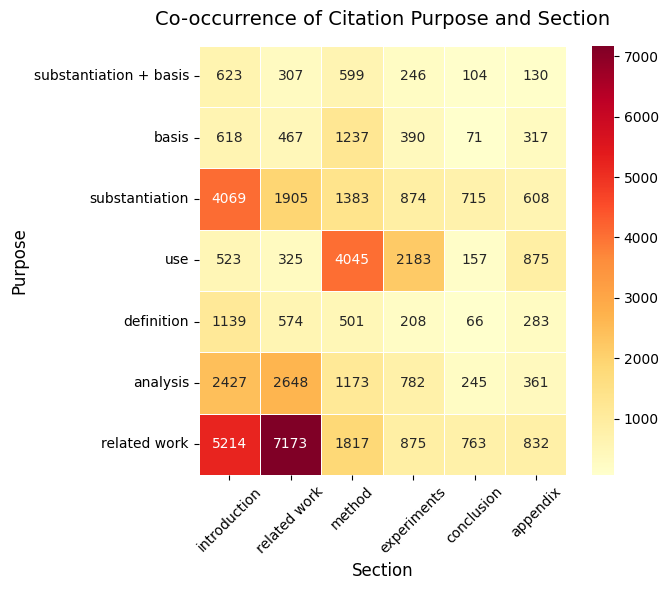

In [ ]:

# Define desired order
purpose_order = [
    'substantiation + basis',
    'basis',
    'substantiation',
    'use',
    'definition',
    'analysis',
    'related work'
]

section_order = [
    "introduction",
    "related work", 
    "method",
    "experiments",
    "conclusion",
    "appendix"
]

# Create co-occurrence matrix and reindex rows
co_occurrence = pd.crosstab(df['purpose'], df['section']).reindex(index=purpose_order, columns=section_order)

# Plot
fig, ax = plt.subplots(figsize=(7, 6))
ax.set_aspect('equal')
# n_rows, n_cols = co_occurrence.shape
# cell_size = 1  # inches per cell
# fig, ax = plt.subplots(figsize=(n_cols * cell_size, n_rows * cell_size))

sns.heatmap(
    co_occurrence,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='white',
    ax=ax
)

ax.set_title('Co-occurrence of Citation Purpose and Section', fontsize=14, pad=15)
ax.set_xlabel('Section', fontsize=12)
ax.set_ylabel('Purpose', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/purpose_section_co-occur.png', dpi=300, bbox_inches='tight')
plt.show()

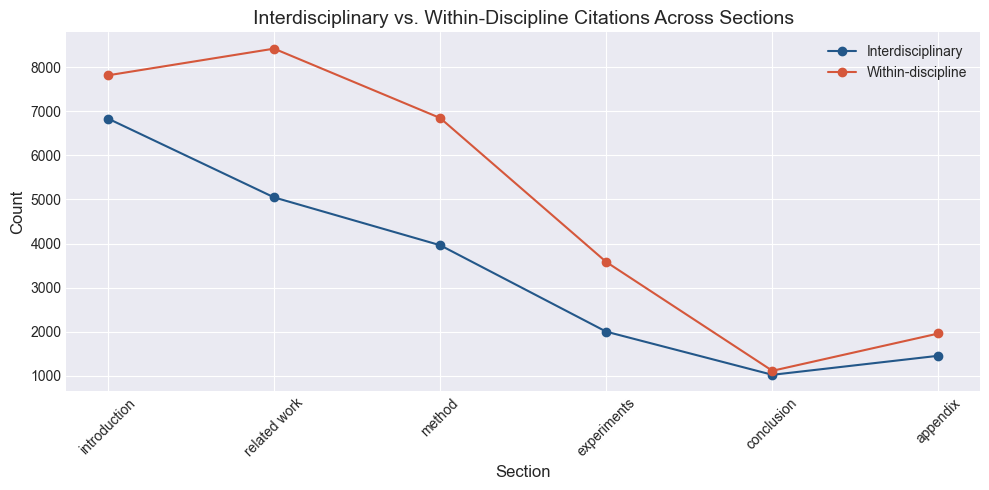

In [ ]:
section_order = [
    "introduction",
    "related work", 
    "method",
    "experiments",
    "conclusion",
    "appendix"
]

# Count interdisciplinary (1) and in-discipline (0) per section
section_counts = df.groupby(['section', 'interdisciplinary']).size().unstack(fill_value=0)
section_counts = section_counts.reindex(section_order)

# Normalize to proportions
section_props = section_counts.div(section_counts.sum(axis=1), axis=0)

# Plot
matplotlib.style.use(MATPLOT_STYLE)
fig, ax = plt.subplots(figsize=(10, 5))

# ax.plot(section_props.index, section_props[1], marker='o', label='Interdisciplinary')
# ax.plot(section_props.index, section_props[0], marker='o', label='Within-discipline')
ax.plot(section_counts.index, section_counts[1], marker='o', label='Interdisciplinary', color=COLORS[6])
ax.plot(section_counts.index, section_counts[0], marker='o', label='Within-discipline', color=COLORS[1])

ax.set_xlabel('Section', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Interdisciplinary vs. Within-Discipline Citations Across Sections', fontsize=14)
ax.legend()
# ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/in_vs_out_across_sec.png", dpi=300, bbox_inches='tight')
plt.show()

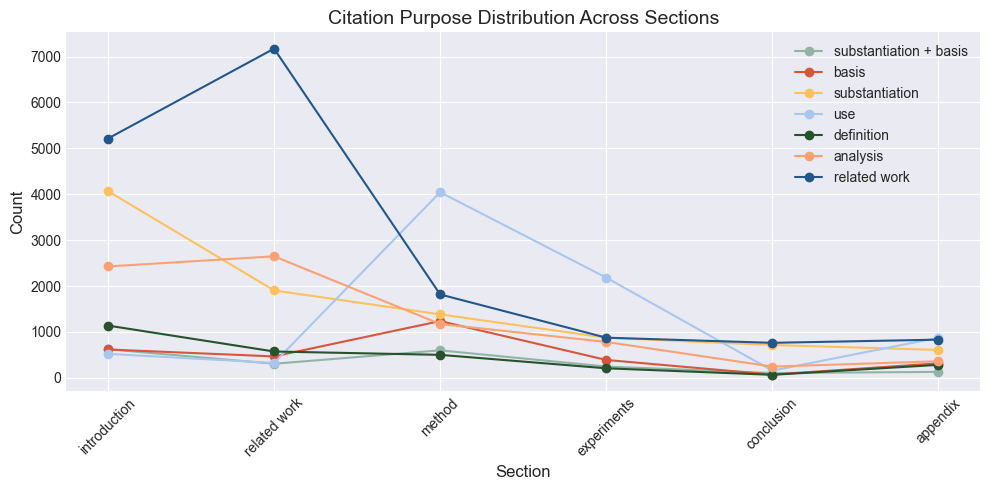

In [ ]:
purpose_order = [
    'substantiation + basis',
    'basis',
    'substantiation',
    'use',
    'definition',
    'analysis',
    'related work'
]

# Count each purpose per section
section_purpose_counts = df.groupby(['section', 'purpose']).size().unstack(fill_value=0)
section_purpose_counts = section_purpose_counts.reindex(index=section_order, columns=purpose_order)

# Plot
matplotlib.style.use(MATPLOT_STYLE)
fig, ax = plt.subplots(figsize=(10, 5))

for i, purpose in enumerate(purpose_order):
    ax.plot(section_purpose_counts.index, section_purpose_counts[purpose],
            marker='o', label=purpose, color=COLORS[i])

ax.set_xlabel('Section', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Citation Purpose Distribution Across Sections', fontsize=14)
ax.legend()
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/purpose_across_sec.png", dpi=300, bbox_inches='tight')
plt.show()

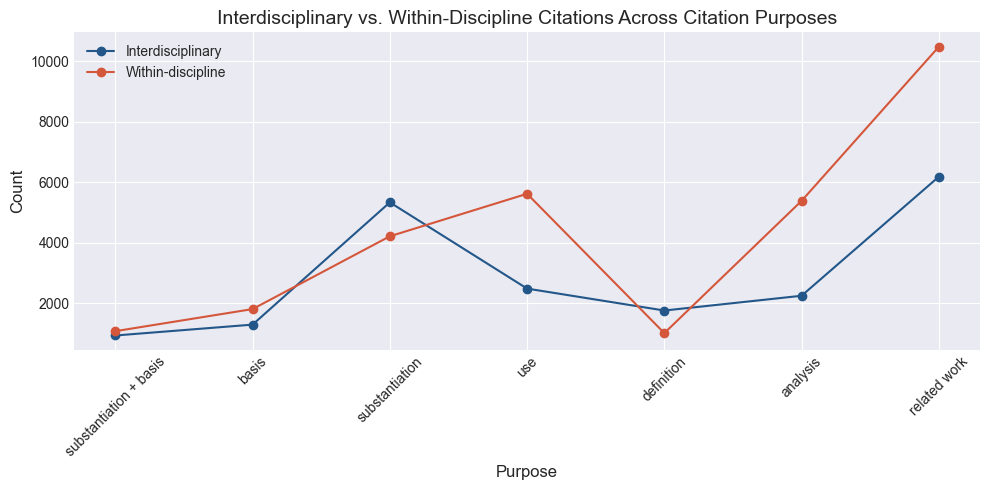

In [ ]:
purpose_order = [
    'substantiation + basis',
    'basis',
    'substantiation',
    'use',
    'definition',
    'analysis',
    'related work'
]

# Count interdisciplinary (1) and in-discipline (0) per purpose
purpose_counts = df.groupby(['purpose', 'interdisciplinary']).size().unstack(fill_value=0)
purpose_counts = purpose_counts.reindex(purpose_order)

# Plot
matplotlib.style.use(MATPLOT_STYLE)
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(purpose_counts.index, purpose_counts[1], marker='o', label='Interdisciplinary', color=COLORS[6])
ax.plot(purpose_counts.index, purpose_counts[0], marker='o', label='Within-discipline', color=COLORS[1])

ax.set_xlabel('Purpose', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Interdisciplinary vs. Within-Discipline Citations Across Citation Purposes', fontsize=14)
ax.legend()
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/in_vs_out_across_purpose.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
print(df['section'].unique())
print(df['interdisciplinary'].unique())
print(df.groupby(['section', 'interdisciplinary']).size())

<StringArray>
['introduction', 'related work',  'experiments',     'appendix',
       'method',   'conclusion']
Length: 6, dtype: str
[1 0]
section       interdisciplinary
appendix      0                    1960
              1                    1455
conclusion    0                    1114
              1                    1023
experiments   0                    3581
              1                    2001
introduction  0                    7813
              1                    6833
method        0                    6845
              1                    3961
related work  0                    8418
              1                    5046
dtype: int64


In [ ]:
# engagement_scores_path = "/Users/alexleto/projects/cross_disciplinary_engagement/scripts/analysis/citations_with_engagement.csv"
eng_df = pd.read_csv(f"{env['FINAL_PRED_PATH']}/citations_with_engagement.csv")

eng_df = eng_df.merge(df, on="citation_id")
eng_df.head()

,article_id_x,citation_id,all_purposes,all_sections,purpose_counts,section_counts,engagement_level,article_id_y,citation_occurrence_id,section,citation_text,citation_context,citation_year,field_of_study,interdisciplinary,count,frequency,purpose
0,1,39,['substantiation + basis'],['introduction'],[1],[1],1,1,0,introduction,"Yahav et al., 2020",Providing quality customer service on social m...,2020,business,1,1,1,substantiation + basis
1,1,37,['definition'],['introduction'],[1],[1],2,1,0,introduction,"Woodcock et al., 2011",Providing quality customer service on social m...,2011,marketing,1,1,1,definition
2,1,22,"['related work', 'substantiation']","['introduction', 'related work']","[1, 1]","[1, 1]",1,1,0,introduction,"Mousavi et al., 2020",While there has been substantial research on c...,2020,information systems,1,2,2,related work
3,1,22,"['related work', 'substantiation']","['introduction', 'related work']","[1, 1]","[1, 1]",1,1,1,related work,Mousavi et al. 2020,Another stream of research examines the role o...,2020,information systems,1,2,2,substantiation
4,1,15,"['related work', 'substantiation']","['introduction', 'related work']","[1, 1]","[1, 1]",1,1,0,introduction,"Herzig et al., 2016",While there has been substantial research on c...,2016,Computer Science,0,2,2,related work


In [ ]:
import sqlite3
con = sqlite3.connect("/Users/alexleto/projects/cross_disciplinary_engagement/data/data.db")
cur = con.cursor()

def get_article_year(article_id):
    cur.execute("SELECT year FROM article WHERE id = ?;", (article_id, ))
    return cur.fetchone()[0]

eng_df["article_year"] = eng_df["article_id_x"].apply(get_article_year)

con.close()


In [ ]:
eng_df = eng_df[["engagement_level", "article_year", "interdisciplinary"]]
eng_df.head()

,engagement_level,article_year,interdisciplinary
0,1,2022,1
1,2,2022,1
2,1,2022,1
3,1,2022,1
4,1,2022,0


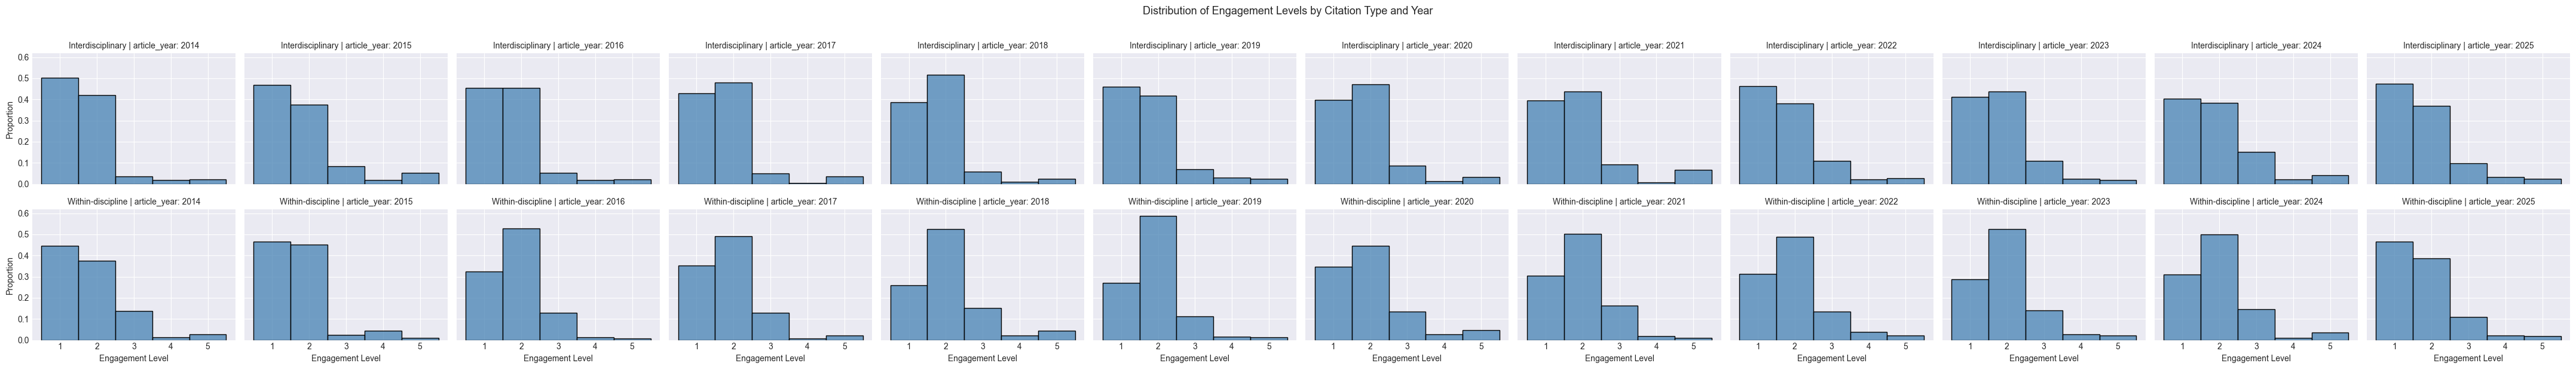

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming your dataframe is called df
# df has columns: engagement_level, article_year, interdisciplinary
df = eng_df
df['citation_type'] = df['interdisciplinary'].map({1: 'Interdisciplinary', 0: 'Within-discipline'})

g = sns.FacetGrid(
    df,
    col='article_year',
    row='citation_type',
    height=3,
    aspect=1.2,
    sharey=True,
    sharex=True
)

g.map_dataframe(
    sns.histplot,
    x='engagement_level',
    bins=range(df['engagement_level'].min(), df['engagement_level'].max() + 2),
    discrete=True,
    color='steelblue',
    stat='proportion'
)

g.set_axis_labels('Engagement Level', 'Proportion')
g.set_titles(row_template='{row_name}', col_template='{col_var}: {col_name}')
g.figure.suptitle('Distribution of Engagement Levels by Citation Type and Year', y=1.02, fontsize=13)

plt.tight_layout()
plt.savefig('engagement_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

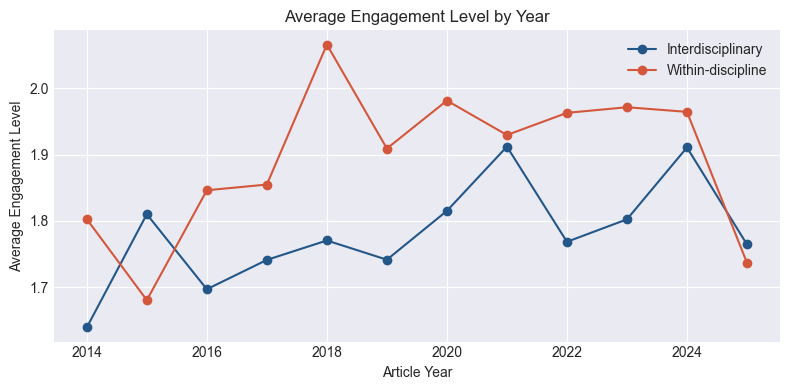

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df['citation_type'] = df['interdisciplinary'].map({1: 'Interdisciplinary', 0: 'Within-discipline'})

avg = df.groupby(['article_year', 'citation_type'])['engagement_level'].mean().reset_index()

fig, ax = plt.subplots(figsize=(8, 4))

color_map = {
    'Interdisciplinary': COLORS[6],
    'Within-discipline': COLORS[1]
}

for label, group in avg.groupby('citation_type'):
    ax.plot(group['article_year'], group['engagement_level'], marker='o', label=label, color=color_map[label])

ax.set_xlabel('Article Year')
ax.set_ylabel('Average Engagement Level')
ax.set_title('Average Engagement Level by Year')
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/avg_engagement_by_article_year.png", dpi=300, bbox_inches='tight')
plt.show()

In [10]:
# repeat some of these with annotated data only

df = pd.read_csv("/Users/aleto/projects/cross_disciplinary_engagement/data/citations.csv")
df = df.dropna(subset=["category"])
df["purpose"] = df["category"]
print(len(df))
df.columns


949


Index(['citation_id', 'citation_text', 'citation_context', 'section',
       'abstract', 'article_id', 'category', 'ann1', 'ann2', 'ann3',
       'interdisciplinary', 'purpose'],
      dtype='str')

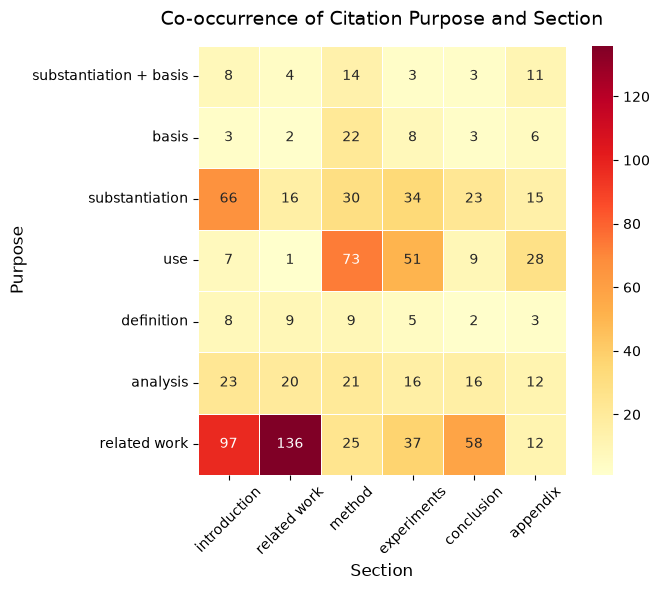

In [14]:


# Define desired order
purpose_order = [
    'substantiation + basis',
    'basis',
    'substantiation',
    'use',
    'definition',
    'analysis',
    'related work'
]

section_order = [
    "introduction",
    "related work", 
    "method",
    "experiments",
    "conclusion",
    "appendix"
]

# Create co-occurrence matrix and reindex rows
co_occurrence = pd.crosstab(df['purpose'], df['section']).reindex(index=purpose_order, columns=section_order)

# Plot
fig, ax = plt.subplots(figsize=(7, 6))
ax.set_aspect('equal')
# n_rows, n_cols = co_occurrence.shape
# cell_size = 1  # inches per cell
# fig, ax = plt.subplots(figsize=(n_cols * cell_size, n_rows * cell_size))

sns.heatmap(
    co_occurrence,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='white',
    ax=ax
)

ax.set_title('Co-occurrence of Citation Purpose and Section', fontsize=14, pad=15)
ax.set_xlabel('Section', fontsize=12)
ax.set_ylabel('Purpose', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/annotated_purpose_section_co-occur.png', dpi=300, bbox_inches='tight')
plt.show()

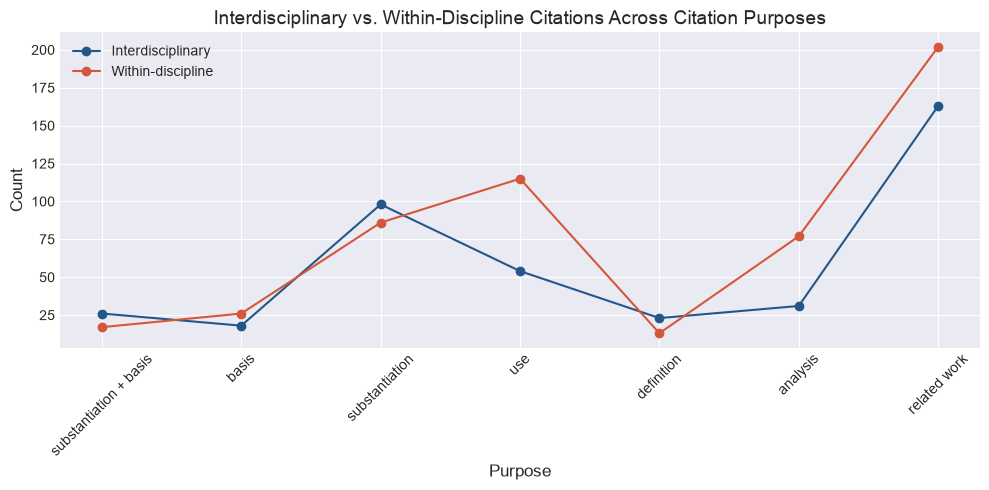

In [16]:
purpose_order = [
    'substantiation + basis',
    'basis',
    'substantiation',
    'use',
    'definition',
    'analysis',
    'related work'
]

# Count interdisciplinary (1) and in-discipline (0) per purpose
purpose_counts = df.groupby(['purpose', 'interdisciplinary']).size().unstack(fill_value=0)
purpose_counts = purpose_counts.reindex(purpose_order)

# Plot
matplotlib.style.use(MATPLOT_STYLE)
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(purpose_counts.index, purpose_counts[1], marker='o', label='Interdisciplinary', color=COLORS[6])
ax.plot(purpose_counts.index, purpose_counts[0], marker='o', label='Within-discipline', color=COLORS[1])

ax.set_xlabel('Purpose', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Interdisciplinary vs. Within-Discipline Citations Across Citation Purposes', fontsize=14)
ax.legend()
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/annotated_in_vs_out_across_purpose.png", dpi=300, bbox_inches='tight')
plt.show()